# Are Longer Books Rated Higher on Goodreads?
**CIS 605 Programming for Data Science Project**

**Student name: Salam Khalid**

## 1. Dataset
**Name:** Goodreads-books  
**Source:** Kaggle, uploaded by Soumik: https://www.kaggle.com/datasets/jealousleopard/goodreadsbooks  
**File:** books.csv (1.56 MB), more than 11,000 rows and 12 columns

**Copy used:** the exact file used in this project is saved in my GitHub repository as `books.csv`, and the notebook loads it from there.

Goodreads is a website where readers rate and review the books they read. Each row in this dataset is one book edition listed on Goodreads. For every book it gives the title, the authors, the average reader rating, how many ratings and written reviews it received, its number of pages, its language, its publication date and its publisher.

### Research question
**Is the length of a book associated with its average rating on Goodreads?**

To answer it, I will compare the average rating of short, medium and long books, measure the correlation between the number of pages and the average rating, and look at how ratings are spread within each length group. The analysis describes associations only. It does not claim that the length of a book causes a higher or lower rating.

### Data dictionary
| Column | Description | Type | Role in the analysis |
|---|---|---|---|
| title | Title of the book as published | Text | Identifying books |
| authors | Author name(s); several authors are separated by "/" | Text | Identifying books |
| average_rating | Average reader rating on Goodreads, from 0 to 5 | Number (decimal) | Outcome: the rating we compare |
| num_pages | Number of pages in the edition | Number (integer) | Main variable: book length |
| ratings_count | Total number of ratings the book received | Number (integer) | Cleaning: a book with no ratings has no real average rating |

The other seven columns (bookID, isbn, isbn13, language_code, text_reviews_count, publication_date, publisher) are not needed to answer the research question.

## 2. Data Inspection and Preparation

### 2.1 Loading the data
I loaded books.csv with Pandas straight from my GitHub repository, so the notebook runs on any computer without downloading the file first. I kept this first table under the name `books_raw` and I do not change it, so the original data stays as it is. A few rows in the file have more fields than the 12 columns, which stops Pandas from reading the file, so I used `on_bad_lines="skip"` to leave them out. I then printed the shape, the column names, the data types and the summary statistics to get a first look at the data.

In [17]:
import pandas as pd

url = "https://raw.githubusercontent.com/salambaniateah-afk/goodreads-project/main/books.csv"
books_raw = pd.read_csv(url, on_bad_lines="skip")

print(books_raw.shape)
print(books_raw.columns)
print(books_raw.dtypes)
books_raw.describe()

(11123, 12)
Index(['bookID', 'title', 'authors', 'average_rating', 'isbn', 'isbn13',
       'language_code', '  num_pages', 'ratings_count', 'text_reviews_count',
       'publication_date', 'publisher'],
      dtype='str')
bookID                  int64
title                     str
authors                   str
average_rating        float64
isbn                      str
isbn13                  int64
language_code             str
  num_pages             int64
ratings_count           int64
text_reviews_count      int64
publication_date          str
publisher                 str
dtype: object


,bookID,average_rating,isbn13,num_pages,ratings_count,text_reviews_count
count,11123.000000,11123.000000,1.112300e+04,11123.000000,1.112300e+04,11123.000000
mean,21310.856963,3.934075,9.759880e+12,336.405556,1.794285e+04,542.048099
std,13094.727252,0.350485,4.429758e+11,241.152626,1.124992e+05,2576.619589
min,1.000000,0.000000,8.987060e+09,0.000000,0.000000e+00,0.000000
25%,10277.500000,3.770000,9.780345e+12,192.000000,1.040000e+02,9.000000
50%,20287.000000,3.960000,9.780582e+12,299.000000,7.450000e+02,47.000000
75%,32104.500000,4.140000,9.780872e+12,416.000000,5.000500e+03,238.000000
max,45641.000000,5.000000,9.790008e+12,6576.000000,4.597666e+06,94265.000000


### 2.2 First look at the data
After loading, the data has 11,123 rows and 12 columns. 4 rows were skipped because they had too many fields. The three columns I need for the analysis already have the right types: average_rating is a decimal number, and num_pages and ratings_count are whole numbers, so no type conversion is needed.

Two things stood out. First, the name of the num_pages column starts with spaces in the file (`"  num_pages"`), so I made a working copy called `books` and removed the extra spaces from all column names. Second, the summary statistics show values that need checking. Some books have 0 pages, some have an average rating of 0, and some have 0 ratings. The longest book has 6,576 pages, while the median is 299 pages. Most ratings sit close to 4: the mean is 3.93, the median is 3.96 and the standard deviation is only 0.35. I check the unusual values in the next steps.

In [18]:
from urllib.request import urlopen

total_rows = len(urlopen(url).read().decode("utf-8").splitlines()) - 1
print("Rows in the file:", total_rows)
print("Rows skipped:", total_rows - len(books_raw))

books = books_raw.copy()
books.columns = books.columns.str.strip()
print(books.columns)

Rows in the file: 11127
Rows skipped: 4
Index(['bookID', 'title', 'authors', 'average_rating', 'isbn', 'isbn13',
       'language_code', 'num_pages', 'ratings_count', 'text_reviews_count',
       'publication_date', 'publisher'],
      dtype='str')


### 2.3 Missing values and duplicates
I counted the empty cells in every column and found none, so no missing values needed to be filled or removed. There are also no fully repeated rows and no repeated bookID values. However, 311 rows share the same title and authors as another row. These are different editions of the same book, for example a hardcover and a paperback, each listed as its own row. If I keep all of them, books with many editions would count more than once in the comparison. I deal with this in the cleaning step by keeping one row for each book.

Looking at some examples, all editions of one book share the same average rating. For example, every edition of 'Salem's Lot by Stephen King has a rating of 4.02. Their page counts are different, though, from 405 to 817 pages, and one edition lists 0 pages. So the rating belongs to the book, while the page count belongs to the edition. For each book I keep the edition with the most ratings, because it is the edition most readers used.

In [19]:
print(books.isnull().sum())

print("Duplicate rows:", books.duplicated().sum())
print("Duplicate bookIDs:", books["bookID"].duplicated().sum())
print("Same title and authors:", books.duplicated(subset=["title", "authors"]).sum())

bookID                0
title                 0
authors               0
average_rating        0
isbn                  0
isbn13                0
language_code         0
num_pages             0
ratings_count         0
text_reviews_count    0
publication_date      0
publisher             0
dtype: int64
Duplicate rows: 0
Duplicate bookIDs: 0
Same title and authors: 311


In [20]:
same_book = books[books.duplicated(subset=["title", "authors"], keep=False)]
same_book.sort_values(["title", "authors"])[["title", "authors", "average_rating", "num_pages", "ratings_count"]].head(10)

,title,authors,average_rating,num_pages,ratings_count
1574,'Salem's Lot,Stephen King,4.02,405,1039
1576,'Salem's Lot,Stephen King,4.02,427,178
1577,'Salem's Lot,Stephen King,4.02,586,25
5300,'Salem's Lot,Stephen King,4.02,817,18
9249,'Salem's Lot,Stephen King,4.02,427,186
1573,'Salem's Lot,Stephen King/Ron McLarty,4.02,17,227
5298,'Salem's Lot,Stephen King/Ron McLarty,4.02,0,56
9130,A Hard Day's Write: The Stories Behind Every B...,Steve Turner,4.18,224,156
9142,A Hard Day's Write: The Stories Behind Every B...,Steve Turner,4.18,224,2072
1164,A History of God: The 4 000-Year Quest of Juda...,Karen Armstrong,3.87,460,38915


### 2.4 Invalid and unusual values
Next I looked for values that cannot be right or that would distort the comparison. I found five problems:
- 76 books have 0 pages. A book cannot have zero pages, so the real length of these books is unknown.
- 197 books have between 1 and 19 pages. When I listed them, most were audiobooks, not printed books. Their titles say so (for example *The Neil Gaiman Audio Collection* and several *BBC Radio 4 Full-Cast* recordings), the authors column often names a narrator next to the author, and one row even lists its author as "NOT A BOOK". For these editions the page count is probably the number of tapes or CDs. *The House on Mango Street*, for example, is listed with 2 pages.
- 80 books have 0 ratings, and 25 books have an average rating of 0. A rating of 0 here does not mean readers disliked the book; it means nobody rated it.
- 673 books have fewer than 10 ratings. Their average depends on very few readers, so one or two people can push it up or down a lot.
- 29 books have more than 1,500 pages. When I listed them, most were box sets and complete collections, such as *Harry Potter Boxed Set Books 1-5* (2,690 pages) and *Plato: Complete Works* (1,838 pages). These are several books sold together, not one long book.

In [21]:
print("Books with 0 pages:", (books["num_pages"] == 0).sum())
print("Books with 0 ratings:", (books["ratings_count"] == 0).sum())
print("Books with average_rating 0:", (books["average_rating"] == 0).sum())
print("Books with fewer than 10 ratings:", (books["ratings_count"] < 10).sum())
print("Books over 1500 pages:", (books["num_pages"] > 1500).sum())

books[books["num_pages"] > 1500][["title", "num_pages"]].head(10)

Books with 0 pages: 76
Books with 0 ratings: 80
Books with average_rating 0: 25
Books with fewer than 10 ratings: 673
Books over 1500 pages: 29


,title,num_pages
4,Harry Potter Boxed Set Books 1-5 (Harry Potte...,2690
6,Harry Potter Collection (Harry Potter #1-6),3342
21,J.R.R. Tolkien 4-Book Boxed Set: The Hobbit an...,1728
406,The Iliad/The Odyssey,1556
420,The Complete Pelican Shakespeare,1808
722,The History of the Lord of the Rings (The Hist...,1680
1053,The Complete Anne of Green Gables Boxed Set (A...,2088
1056,The New Annotated Sherlock Holmes: The Complet...,1878
2566,Plato: Complete Works,1838
3182,Rabbit Angstrom: The Four Novels,1520


In [22]:
very_short = books[(books["num_pages"] > 0) & (books["num_pages"] < 20)]
print("Books with 1 to 19 pages:", len(very_short))

very_short.sort_values("num_pages")[["title", "authors", "num_pages", "ratings_count"]].head(15)

Books with 1 to 19 pages: 197


,title,authors,num_pages,ratings_count
3454,Essential Welty: Why I Live at the P.O. A Mem...,Eudora Welty,1,92
4945,Antibodies,Charles Stross/Shandra Marie/Jared Doreck,1,67
5755,The Best American Mystery Stories 2003,Michael Connelly/Otto Penzler,1,5
5779,The Best American Mystery Stories 2002,James Ellroy/Otto Penzler/John Biguenet/Michae...,1,0
4944,Lobsters,Charles Stross/Shandra Marie/Jared Doreck,1,158
4270,The Return of the King (The Lord of the Rings ...,Brian Sibley/J.R.R. Tolkien,1,17
5650,Meditations for Manifesting: Morning and Eveni...,Wayne W. Dyer,1,338
5944,The Neil Gaiman Audio Collection,Neil Gaiman,1,1666
8505,LT's Theory of Pets,Stephen King,1,2824
9036,There Was a Cold Lady Who Swallowed Some Snow!,Lucille Colandro/Jared Lee/Skip Hinnant,1,14


### 2.5 Cleaning the data
I cleaned a separate table called `books_clean`, so `books_raw` and `books` stay unchanged. I made the changes in this order and printed the number of rows after each one:
1. Removed the 76 books with 0 pages, because their length is unknown (11,123 to 11,047 rows).
2. Removed the 197 books with 1 to 19 pages, because most of them are audiobooks and their page count does not measure length (11,047 to 10,850 rows).
3. Removed books with fewer than 10 ratings, because their average rating is not reliable. This also removed every book with 0 ratings or an average rating of 0 (10,850 to 10,221 rows).
4. Removed books with more than 1,500 pages, because most of them are box sets of several books (10,221 to 10,193 rows).
5. Kept one edition of each book, the one with the most ratings (10,193 to 9,921 rows).

I removed the invalid rows before the duplicate editions, so the edition I keep always has a real page count. Finally, I kept only the five columns from the data dictionary.

In total I removed 1,202 rows, about 11% of the data, which leaves 9,921 books for the analysis. After cleaning, the average rating has a mean of 3.94, a median of 3.96 and a standard deviation of 0.27, and the lowest rating is 2.40. The number of pages goes from 20 to 1,500, with a median of 304, and half of the books have between 208 and 416 pages.

In [23]:
print("Rows before cleaning:", len(books))

books_clean = books[books["num_pages"] > 0]
print("After removing books with 0 pages:", len(books_clean))

books_clean = books_clean[books_clean["num_pages"] >= 20]
print("After removing books under 20 pages:", len(books_clean))

books_clean = books_clean[books_clean["ratings_count"] >= 10]
print("After removing books with fewer than 10 ratings:", len(books_clean))

books_clean = books_clean[books_clean["num_pages"] <= 1500]
print("After removing books over 1500 pages:", len(books_clean))

books_clean = books_clean.sort_values("ratings_count", ascending=False)
books_clean = books_clean.drop_duplicates(subset=["title", "authors"], keep="first")
print("After keeping one edition per book:", len(books_clean))

books_clean = books_clean[["title", "authors", "average_rating", "num_pages", "ratings_count"]].reset_index(drop=True)
books_clean.describe()

Rows before cleaning: 11123
After removing books with 0 pages: 11047
After removing books under 20 pages: 10850
After removing books with fewer than 10 ratings: 10221
After removing books over 1500 pages: 10193
After keeping one edition per book: 9921


,average_rating,num_pages,ratings_count
count,9921.000000,9921.000000,9.921000e+03
mean,3.944371,341.617377,1.999820e+04
std,0.274961,207.736219,1.189085e+05
min,2.400000,20.000000,1.000000e+01
25%,3.780000,208.000000,1.820000e+02
50%,3.960000,304.000000,1.037000e+03
75%,4.130000,416.000000,6.193000e+03
max,4.910000,1500.000000,4.597666e+06


## 3. Analysis

### 3.1 Grouping books by length
To compare books of different lengths, I added a column called `length_group` with three groups: short (200 pages or fewer), medium (201 to 400 pages) and long (401 to 1,500 pages). I chose these cut points because they are close to the first and third quartiles of num_pages (208 and 416 pages), and they are round numbers that are easy to read. The groups contain 2,368 short books (24%), 4,827 medium books (49%) and 2,726 long books (27%), so each group is large enough to compare.

In [24]:
books_clean["length_group"] = pd.cut(books_clean["num_pages"],
                                     bins=[0, 200, 400, 1500],
                                     labels=["short", "medium", "long"])

books_clean["length_group"].value_counts().sort_index()

length_group
short     2368
medium    4827
long      2726
Name: count, dtype: int64

### 3.2 Descriptive statistics
I used NumPy to calculate the mean, median, standard deviation, minimum and maximum of the two main columns.

The average rating has a mean of 3.94, a median of 3.96 and a standard deviation of only 0.27, and it ranges from 2.40 to 4.91. So most books are rated close to 4, and very few books are rated far from that. The mean is a little lower than the median, which means a small number of books with low ratings pull the mean down.

The number of pages has a mean of 341.62, a median of 304 and a standard deviation of 207.74, and it ranges from 20 to 1,500. Here the mean is higher than the median, because a smaller number of very long books pull the mean up. Book length varies a lot, while ratings vary very little.

In [25]:
import numpy as np

ratings = books_clean["average_rating"].to_numpy()
pages = books_clean["num_pages"].to_numpy()

stats = pd.DataFrame({
    "average_rating": [np.mean(ratings), np.median(ratings), np.std(ratings, ddof=1), np.min(ratings), np.max(ratings)],
    "num_pages": [np.mean(pages), np.median(pages), np.std(pages, ddof=1), np.min(pages), np.max(pages)]
}, index=["mean", "median", "std", "min", "max"])

stats.round(2)

,average_rating,num_pages
mean,3.94,341.62
median,3.96,304.00
std,0.27,207.74
min,2.40,20.00
max,4.91,1500.00


### 3.3 Comparing short, medium and long books
I grouped the books by `length_group` and calculated the rating statistics for each group.

Long books have the highest ratings, with a mean of 4.03 and a median of 4.04. Short books come next, with a mean of 3.94, and medium books have the lowest ratings, with a mean of 3.90. So the ratings do not simply rise as books get longer: they dip slightly from short to medium books and then rise for long books.

The gap between long and medium books is 0.13 points. That looks small on a five-point scale, but it is about half of the standard deviation of all ratings (0.27), so it is a noticeable difference in this data. Long books also have the smallest spread (standard deviation 0.25), which means their ratings are more consistent.

One possible reason is that readers who choose a long book are often already fans of the author or the genre, so they may rate it more kindly. This data cannot test that reason, and the comparison does not show that length itself causes a higher rating.

In [26]:
group_stats = books_clean.groupby("length_group", observed=True)["average_rating"].agg(["count", "mean", "median", "std", "min", "max"])
group_stats.round(2)

,count,mean,median,std,min,max
length_group,,,,,,
short,2368,3.94,3.96,0.29,2.80,4.91
medium,4827,3.90,3.92,0.27,2.40,4.72
long,2726,4.03,4.04,0.25,2.77,4.82


### 3.4 Correlation between length and rating
I calculated the Pearson correlation between num_pages and average_rating with NumPy and checked it with Pandas. Both gave r = 0.187.

The value is positive, so longer books tend to have slightly higher ratings. But it is weak: it is much closer to 0 than to 1. Squaring it gives about 0.035, which means the number of pages accounts for only about 3.5% of the differences in ratings between books. The other 96.5% comes from other things, such as the author, the genre or the story itself.

This fits the group comparison. Long books are rated a little higher on average, but there are many highly rated short books and many low-rated long books, so length alone tells us little about how a single book will be rated. A correlation also does not show cause and effect.

In [27]:
r = np.corrcoef(books_clean["num_pages"], books_clean["average_rating"])[0, 1]
print("Correlation between num_pages and average_rating:", round(r, 3))

print("Check with Pandas:", round(books_clean["num_pages"].corr(books_clean["average_rating"]), 3))

Correlation between num_pages and average_rating: 0.187
Check with Pandas: 0.187


## 4. Visualizations

### 4.1 Mean rating by length group (bar chart)
Figure 1 shows the mean rating of each length group. Long books have the highest bar (4.03), followed by short books (3.94) and medium books (3.90). I started the vertical axis at 0, so the bars show the real size of the gap. Starting it near 3.9 would make a difference of 0.13 look much bigger than it is. The chart shows that long books are rated slightly higher, but the three bars are almost the same height, which matches the weak relationship found in Section 3.

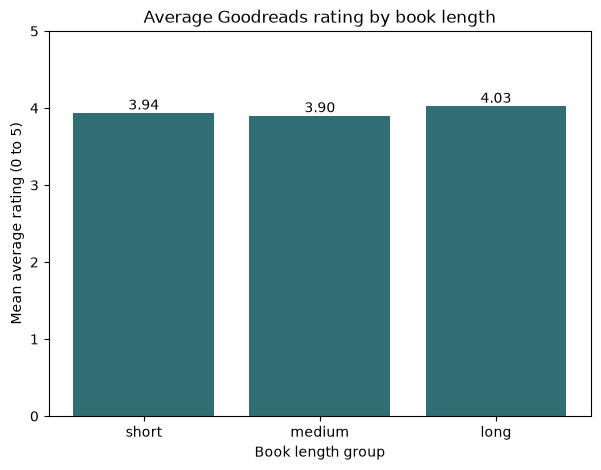

In [28]:
import matplotlib.pyplot as plt
import os

os.makedirs("images", exist_ok=True)

mean_by_group = books_clean.groupby("length_group", observed=True)["average_rating"].mean()

plt.figure(figsize=(7, 5))
bars = plt.bar(mean_by_group.index.astype(str), mean_by_group.values, color="#2f6f73")
plt.bar_label(bars, fmt="%.2f")
plt.ylim(0, 5)
plt.title("Average Goodreads rating by book length")
plt.xlabel("Book length group")
plt.ylabel("Mean average rating (0 to 5)")
plt.savefig("images/1_rating_by_length_group.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.2 Distribution of ratings (histogram)
Figure 2 shows how the ratings of all 9,921 books are spread. The shape is close to a bell curve with its peak just under 4.0, and the dashed line marks the mean of 3.94. Almost all books are rated between 3.5 and 4.5, and the tallest bar alone holds more than 1,300 books. The left side stretches further than the right: a few books go down to about 2.5, while hardly any reach 4.8 or above. This longer left tail is why the mean (3.94) sits a little below the median (3.96).

For the research question, this chart explains why the differences between length groups are small. Most books are rated close to 4, so there is not much room for any group to stand far above or below the others.

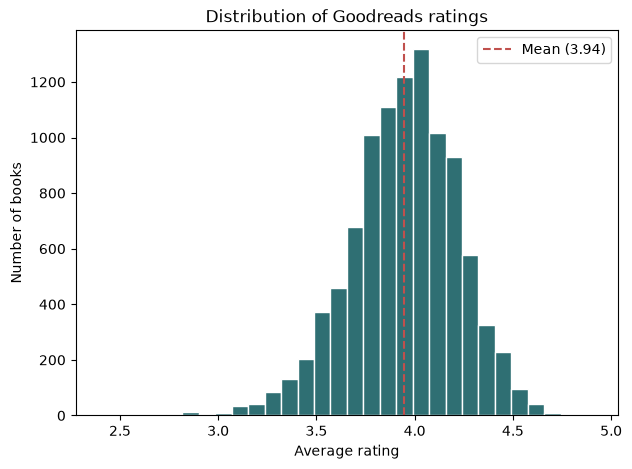

In [29]:
mean_rating = books_clean["average_rating"].mean()

plt.figure(figsize=(7, 5))
plt.hist(books_clean["average_rating"], bins=30, color="#2f6f73", edgecolor="white")
plt.axvline(mean_rating, color="#c0504d", linestyle="--", label=f"Mean ({mean_rating:.2f})")
plt.title("Distribution of Goodreads ratings")
plt.xlabel("Average rating")
plt.ylabel("Number of books")
plt.legend()
plt.savefig("images/2_rating_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.3 Number of pages vs. rating (scatter plot)
Figure 3 places every book as one dot, with its number of pages on the horizontal axis and its rating on the vertical axis. I made the dots small and partly transparent, so the darker areas show where most books are. The red line is the straight line that fits the dots best, which I found with NumPy's `polyfit`.

Most books sit between about 100 and 500 pages, with ratings between about 3.3 and 4.5. The trend line rises slowly, from about 3.9 for the shortest books to about 4.2 for the longest, which agrees with the positive correlation of 0.19. But at every length the dots spread widely above and below the line. Very low ratings, under 3.0, appear almost only among books under 600 pages, while books over 800 pages are fewer and are rarely rated under 3.5.

So the chart answers the research question in the same way as the numbers: longer books tend to be rated a little higher, but the relationship is weak, and length does not predict the rating of a single book well.

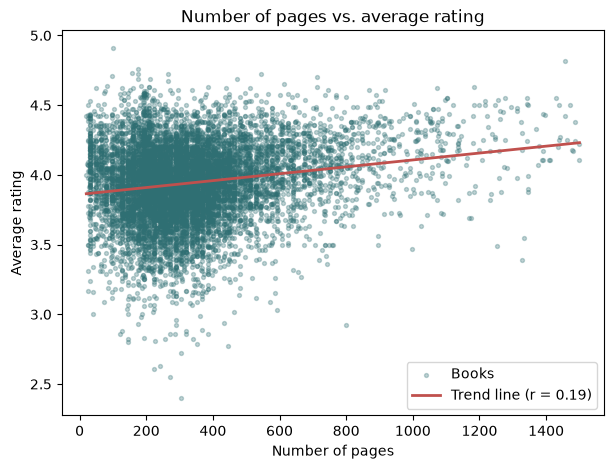

In [30]:
slope, intercept = np.polyfit(books_clean["num_pages"], books_clean["average_rating"], 1)
x_line = np.array([20, 1500])
y_line = slope * x_line + intercept

plt.figure(figsize=(7, 5))
plt.scatter(books_clean["num_pages"], books_clean["average_rating"], s=8, alpha=0.3, color="#2f6f73", label="Books")
plt.plot(x_line, y_line, color="#c0504d", linewidth=2, label=f"Trend line (r = {r:.2f})")
plt.title("Number of pages vs. average rating")
plt.xlabel("Number of pages")
plt.ylabel("Average rating")
plt.legend()
plt.savefig("images/3_pages_vs_rating.png", dpi=150, bbox_inches="tight")
plt.show()

### 4.4 Spread of ratings within each group (boxplot)
Figure 4 shows a box for each length group. The red line in each box is the median, and the box covers the middle half of the books in that group, from the 25th to the 75th percentile. The whiskers reach most of the other values, and the circles are outliers that sit far from the rest.

The box for long books sits higher than the other two: its median is about 4.04, and its middle half runs from about 3.9 to 4.2. The boxes for short and medium books sit a little lower, with medians of about 3.96 and 3.92. Still, the three boxes overlap a lot, so many short and medium books are rated as highly as a typical long book.

The outliers tell the same story from another side. Medium books have the most low outliers, going down to 2.40, while long books have the fewest. A count confirms this: only 3 long books are rated under 3.0, compared with 18 medium books and 7 short books. All three groups have a few books rated above 4.6.

This plot adds to the bar chart in Figure 1. The bar chart shows only the averages, while the boxplot shows that the whole group of long books sits slightly higher and has fewer very low ratings, even though the groups overlap heavily.

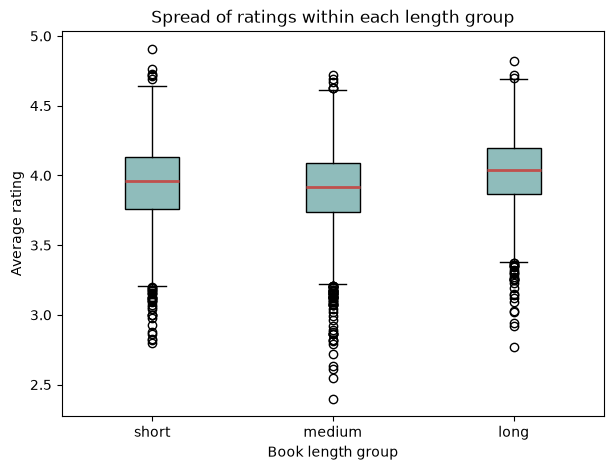

In [31]:
groups = ["short", "medium", "long"]
data = [books_clean.loc[books_clean["length_group"] == g, "average_rating"] for g in groups]

plt.figure(figsize=(7, 5))
plt.boxplot(data, patch_artist=True,
            boxprops=dict(facecolor="#8fbcbb"),
            medianprops=dict(color="#c0504d", linewidth=2))
plt.xticks([1, 2, 3], groups)
plt.title("Spread of ratings within each length group")
plt.xlabel("Book length group")
plt.ylabel("Average rating")
plt.savefig("images/4_rating_boxplot_by_group.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Discussion of the findings
Before writing the findings, I counted the books rated under 3.0 in each length group, to confirm what the boxplot shows.

In [32]:
low_rated = books_clean[books_clean["average_rating"] < 3.0]
low_rated.groupby("length_group", observed=True).size()

length_group
short      7
medium    18
long       3
dtype: int64

### 5.1 Three evidence-based findings
1. **Long books have the highest average rating.** Books with 401 to 1,500 pages have a mean rating of 4.03, compared with 3.94 for short books and 3.90 for medium books (Figure 1). The pattern is not a steady rise: ratings dip slightly from short to medium books and then rise for long books.

2. **The relationship between length and rating is positive but weak.** The correlation between the number of pages and the average rating is r = 0.187, so length accounts for only about 3.5% of the differences in ratings. In the scatter plot (Figure 3) the trend line rises slowly, but books of every length are spread widely above and below it.

3. **Long books are rated more consistently, with fewer very low ratings.** Long books have the smallest standard deviation (0.25, compared with 0.29 for short books and 0.27 for medium books), and their box sits higher in Figure 4. Only 3 of the 2,726 long books (0.1%) are rated under 3.0, compared with 18 of the 4,827 medium books (0.4%) and 7 of the 2,368 short books (0.3%).

### 5.2 Limitation
The main limitation is that the dataset has no genre column. Long books may be rated higher because of their length, or because long books are more often from genres or authors that readers already love, such as fantasy series and well-known classics. Without genre information, I cannot separate these explanations, so I can only say that length and rating are associated, not that one causes the other.

### 5.3 Recommendation
A next step would be to add the genre of each book, for example by matching the books with another Goodreads dataset that includes genres, and then repeat the comparison inside each genre. If long books are still rated higher within the same genre, the link with length would be stronger. A statistical test, such as ANOVA, could also show whether the differences between the three length groups are larger than chance.

### 5.4 Patterns, relationships and conclusions
**Patterns:** Goodreads ratings are packed closely around 4, with most books between 3.5 and 4.5. Long books sit slightly higher and have fewer very low ratings, while medium books have the lowest average.

**Relationships:** the number of pages and the average rating have a positive but weak relationship (r = 0.187). Length explains only about 3.5% of the differences in ratings.

**Key conclusions:** to answer the research question, yes, longer books on Goodreads tend to have slightly higher average ratings. Long books average 4.03, compared with 3.90 for medium books. But the effect is small, books of every length can be rated high or low, and this data does not show that length causes the higher ratings. Other things, such as genre and author, probably matter much more.